# R1 · Index cost (Fig 2)

Collects the build records of the index cache (per dataset × seed: sizes, storage of every index, build seconds
per stage, peak memory) and the cell / gene ladders of Fig 2D–E.

* **Prerequisites:** `R0_index_cache` (the 40 timed builds). The ladders are **not** recomputed here: their point records
  `results/index_cost/ladder/*.json` come from the earlier ladder runs (tonsil cell ladder; lymph node 5k gene ladder,
  which needs ~740 GB of memory). They were made with the frozen method and re-tagged `method-v2` at the rename.
* **Writes:** `results/index_cost/builds.csv` (one row per build) and `results/index_cost/ladder.csv` (one row per ladder point).
* **Runtime / memory:** seconds; < 1 GB.

In [1]:
import json
import shutil
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "datasets.yaml").exists())
sys.path.insert(0, str(ROOT / "experiments" / "common"))
import pandas as pd

import data
import results_io as rio

TOPIC = "index_cost"
LADDER = rio.topic(TOPIC) / "ladder"
OLD_LADDER = data.RESULTS / "fig2_cost" / "ladder"  # the earlier runs (copied once; removed in the final cleanup)
SPEC = {"spindle_pct": (10.5, 12.4), "spindle_partial_pct": (13.6, 14.4)}  # SPINDLE_LITE.md / SPINDLE_PARTIAL.md ranges
CELLS = [1_000, 2_000, 5_000, 10_000, 20_000, 50_000, 100_000, 200_000, 500_000, 1_000_000, None]
GENES = [250, 400, 500, 750, 1000, 1500]  # 2,000 hits the layout's recursion limit; stopped at 1,500
print(data.stamp())

{'tag': 'method-v2', 'describe': 'method-v2-dirty', 'commit': '8040f91'}


## Builds

In [2]:
rows, missing = [], []
for key in data.indexed_keys():
    for seed in data.SEEDS:
        f = data.cache_dir(key, seed) / "build.json"
        if f.exists():
            rows.append(json.loads(f.read_text()))
        else:
            missing.append(f"{key}/seed{seed}")
df = pd.DataFrame(rows)
df["build_s"] = df[["prepare_s", "layout_s", "naive_s", "spindle_s", "naive_partial_s", "spindle_partial_s"]].sum(axis=1)
if missing or set(df.tag) != {data.TAG}:
    raise SystemExit(f"incomplete: missing {missing}, tags {sorted(set(df.tag))}")
rio.write_csv(df.drop(columns=["niche_sizes"]), TOPIC, "builds.csv",
              "one row per (dataset, seed) build: sizes, niches, blocks, bytes of every index, build seconds per stage "
              "(build_s = prepare + layout + naive + spindle + naive_partial + spindle_partial), peak memory, host")
print(f"tags {sorted(set(df.tag))}, hosts {sorted(set(df.host))}")

wrote results/index_cost/builds.csv: 40 rows
tags ['method-v2'], hosts ['ROSALIND-CPU1.vuds.vanderbilt.edu']


In [3]:
g = df.groupby("key", sort=False)
pd.DataFrame({
    "train": g.n_train.median(), "test": g.n_test.median(), "niches": g.n_niches.agg(lambda s: f"{s.min()}-{s.max()}"),
    "blocks": g.n_blocks.agg(lambda s: f"{s.min()}-{s.max()}"),
    "spindle_pct": g.spindle_pct.mean(), "spindle_partial_pct": g.spindle_partial_pct.mean(),
    "build_s": g.build_s.mean(), "build_sd": g.build_s.std(), "spindle_s": g.spindle_s.mean(),
    "spindle_partial_s": g.spindle_partial_s.mean(), "peak_gb": g.peak_gb_spindle_partial.mean(),
}).round(2)

,train,test,niches,blocks,spindle_pct,spindle_partial_pct,build_s,build_sd,spindle_s,spindle_partial_s,peak_gb
key,,,,,,,,,,,
skin_melanoma,839.0,93.0,3-4,58-82,11.32,13.71,27.33,0.31,0.73,4.80,3.09
kidney_nondiseased,705.0,78.0,2-3,40-60,11.26,14.34,23.79,0.45,0.56,3.40,2.89
breast_cancer,1840.0,204.0,3-4,45-67,11.22,13.70,36.42,0.42,1.44,7.09,4.33
lung_cancer,1535.0,170.0,3-4,57-77,11.20,13.70,36.93,0.40,1.37,6.73,5.41
pancreatic_cancer,2061.0,229.0,4-4,108-111,11.97,14.49,62.62,2.41,2.13,10.79,9.49
lymph_node,2354.0,261.0,5-7,103-146,10.84,13.94,52.02,0.32,2.05,11.00,7.10
lymph_node_5k,6972.0,774.0,15-17,302-345,11.45,13.73,168.05,7.04,6.94,35.15,26.38
brain_cancer,9558.0,1062.0,16-18,418-480,11.56,14.14,259.72,12.55,10.53,50.36,51.20


Storage of Spindle (% of Spindle-naive) and Spindle partial (% of the Spindle-naive gene-set index) against the ranges
of the method specification (measured there on a 100-held-out split).

In [4]:
for col, (lo, hi) in SPEC.items():
    out = df[(df[col] < lo) | (df[col] > hi)]
    print(f"{col}: {df[col].min():.2f}-{df[col].max():.2f} % over all builds (spec {lo}-{hi} %); {len(out)} builds outside")

spindle_pct: 10.31-12.68 % over all builds (spec 10.5-12.4 %); 4 builds outside
spindle_partial_pct: 13.45-14.62 % over all builds (spec 13.6-14.4 %); 10 builds outside


## Ladders
`naive_build_s` = prepare + layout + naive, Spindle-naive's full build (file loading excluded).

In [5]:
LADDER.mkdir(parents=True, exist_ok=True)
if OLD_LADDER.exists():
    for f in sorted(OLD_LADDER.glob("*.json")):
        if not (LADDER / f.name).exists():
            shutil.copy2(f, LADDER / f.name)
lad = pd.DataFrame([json.loads(f.read_text()) for f in sorted(LADDER.glob("*.json"))])
lad["naive_build_s"] = lad[["prepare_s", "layout_s", "naive_s"]].sum(axis=1)
lad = lad.sort_values(["ladder", "n_cells", "p"])
if set(lad.tag) != {data.TAG}:
    raise SystemExit(f"ladder tags {sorted(set(lad.tag))}")
rio.write_csv(lad, TOPIC, "ladder.csv", "one row per ladder point (cells: tonsil subsampled; genes: lymph node 5k top-p "
              "genes): sizes, bytes of every index, build seconds per stage, naive_build_s, peak memory")
for ladder, xs in (("cells", CELLS), ("genes", GENES)):
    have = {f.stem.split("_", 1)[1] for f in LADDER.glob(f"{ladder}_*.json")}
    print(f"{ladder}: missing {[x for x in xs if ('full' if x is None else str(x)) not in have]}")
cols = ["ladder", "n_cells", "p", "n_train", "n_niches", "n_blocks", "naive_build_s", "spindle_s", "naive_partial_s",
        "spindle_partial_s", "peak_gb_spindle_partial", "bytes_naive", "bytes_spindle", "bytes_spindle_partial"]
lad[cols].round(2)

wrote results/index_cost/ladder.csv: 17 rows
cells: missing []
genes: missing []


,ladder,n_cells,p,n_train,n_niches,n_blocks,naive_build_s,spindle_s,naive_partial_s,spindle_partial_s,peak_gb_spindle_partial,bytes_naive,bytes_spindle,bytes_spindle_partial
0,cells,1000,377,12,1,18,13.18,0.00,0.01,0.08,0.99,244320,26988,32768
4,cells,2000,377,15,1,19,12.87,0.00,0.01,0.09,0.98,267000,27653,37043
7,cells,5000,377,48,1,16,13.32,0.01,0.04,0.26,0.99,1194432,141752,153024
1,cells,10000,377,119,1,20,14.10,0.05,0.07,0.59,0.98,1917328,201116,273644
5,cells,20000,377,162,2,41,14.55,0.06,0.10,0.78,1.04,2675440,291702,379356
8,cells,50000,377,555,2,37,18.08,0.57,0.39,3.33,2.38,11979828,1388374,1586056
2,cells,100000,377,792,3,59,20.40,0.71,0.49,4.69,2.88,14425876,1513806,1992766
6,cells,200000,377,2008,5,99,33.12,1.77,1.23,9.34,6.12,36522696,4323736,5042772
9,cells,500000,377,6017,9,175,78.88,5.54,3.55,26.20,17.08,109595528,13360895,15149989
3,cells,1000000,377,8060,14,273,111.23,7.32,5.06,35.15,22.80,145809296,18047545,20151994


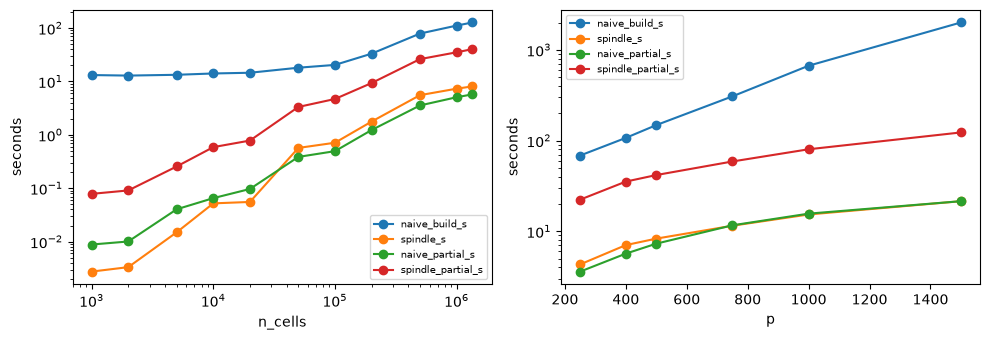

In [6]:
import matplotlib.pyplot as plt

fig, axs = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, ladder, x in ((axs[0], "cells", "n_cells"), (axs[1], "genes", "p")):
    d = lad[lad.ladder == ladder]
    for col in ("naive_build_s", "spindle_s", "naive_partial_s", "spindle_partial_s"):
        ax.plot(d[x], d[col], "o-", label=col)
    ax.set_yscale("log"); ax.set_xscale("log" if ladder == "cells" else "linear")
    ax.set_xlabel(x); ax.set_ylabel("seconds"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

In [7]:
rio.write_manifest(TOPIC, "R1_index_cost.ipynb", inputs=["results/_cache/*/seed*/build.json (R0_index_cache)",
                                                          "results/index_cost/ladder/*.json (earlier ladder runs)"])

wrote results/index_cost/manifest.json: 2 files; peak memory 0.16 GB


{'topic': 'index_cost',
 'notebook': 'R1_index_cost.ipynb',
 'date': '2026-10-31 23:50',
 'tag': 'method-v2',
 'describe': 'method-v2-dirty',
 'commit': '8040f91',
 'inputs': ['results/_cache/*/seed*/build.json (R0_index_cache)',
  'results/index_cost/ladder/*.json (earlier ladder runs)'],
 'peak_rss_gb': 0.16,
 'notes': '',
 'files': {'builds.csv': {'description': 'one row per (dataset, seed) build: sizes, niches, blocks, bytes of every index, build seconds per stage (build_s = prepare + layout + naive + spindle + naive_partial + spindle_partial), peak memory, host',
   'rows': 40,
   'bytes': 22078},
  'ladder.csv': {'description': 'one row per ladder point (cells: tonsil subsampled; genes: lymph node 5k top-p genes): sizes, bytes of every index, build seconds per stage, naive_build_s, peak memory',
   'rows': 17,
   'bytes': 9142}}}